## CL-1 Lab Assignment 4 (Group B): Data Visualization using Matplotlib
### Analyzing Air Quality Index (AQI) Trends in a City

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True

In [2]:
FILE = "City_Air_Quality.csv"

try:
    df = pd.read_csv(FILE)
except FileNotFoundError:
    print("City_Air_Quality.csv was not found!")
else:
    print(f"Loaded {FILE}")

display(df.head())

Loaded City_Air_Quality.csv


,Date,PM2.5,PM10,CO,AQI
0,2025-01-01,70.484907,67.928256,0.841776,117.5
1,2025-01-02,46.280286,101.627874,1.262746,95.9
2,2025-01-03,78.508122,114.068827,1.276999,141.8
3,2025-01-04,81.930165,124.655558,1.675716,153.2
4,2025-01-05,29.881367,127.780664,1.492289,81.2


In [3]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
print("\nData types:")
display(df.dtypes.to_frame("dtype"))
print("\nMissing values:")
display(df.isna().sum().to_frame("missing"))
print("\nSummary statistics:")
display(df.describe(include="all").T)

Shape: (60, 5)

Columns:
['Date', 'PM2.5', 'PM10', 'CO', 'AQI']

Data types:


,dtype
Date,object
PM2.5,float64
PM10,float64
CO,float64
AQI,float64



Missing values:


,missing
Date,0
PM2.5,0
PM10,0
CO,0
AQI,0



Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Date,60,60,2025-01-01,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PM2.5,60.0,NaN,NaN,NaN,66.175138,14.141657,29.881367,56.344877,67.200736,76.450059,103.549657
PM10,60.0,NaN,NaN,NaN,105.347769,19.254347,66.816989,94.722651,104.440085,121.227305,150.044472
CO,60.0,NaN,NaN,NaN,1.182678,0.356892,0.453784,0.90538,1.1546,1.347814,2.219852
AQI,60.0,NaN,NaN,NaN,122.491667,19.695515,81.2,105.325,123.5,135.3,176.3


In [4]:
# Identify likely date, AQI, and pollutant columns from common naming conventions.
date_candidates = [c for c in df.columns if c.lower() in {"date", "datetime", "timestamp", "time"} or "date" in c.lower()]
aqi_candidates = [c for c in df.columns if "aqi" in c.lower()]

date_col = date_candidates[0] if date_candidates else None
aqi_col = aqi_candidates[0] if aqi_candidates else None

if date_col:
    df[date_col] = pd.to_datetime(df[date_col], errors="coerce")
    print("Date variable:", date_col)
else:
    print("No date-like column was automatically identified.")

if aqi_col:
    print("AQI variable:", aqi_col)
else:
    print("No AQI column was automatically identified.")

pollutant_keywords = ["pm2.5", "pm25", "pm10", "co", "no2", "so2", "o3"]
pollutant_cols = [c for c in df.columns if any(k in c.lower().replace(" ", "") for k in pollutant_keywords)]
print("Pollutant variables:", pollutant_cols)

Date variable: Date
AQI variable: AQI
Pollutant variables: ['PM2.5', 'PM10', 'CO']


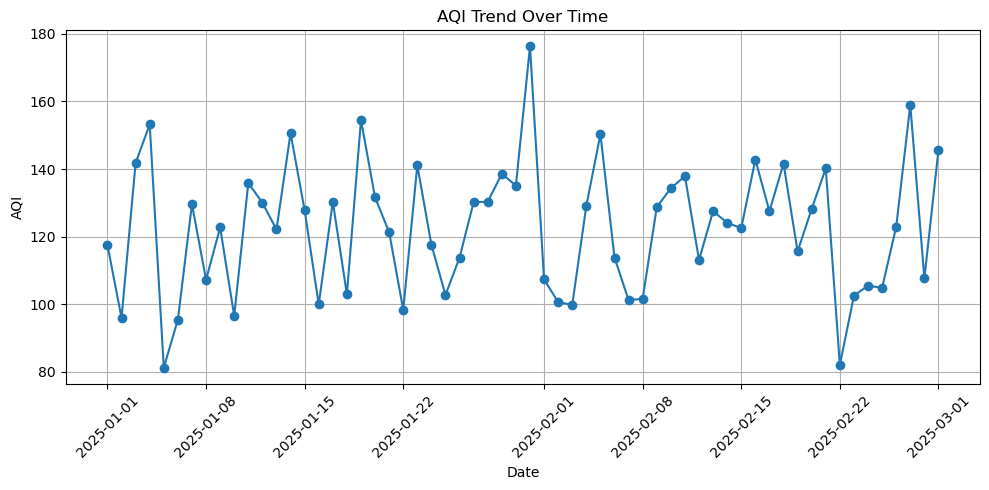

In [5]:
if date_col and aqi_col:
    plot_df = df.dropna(subset=[date_col, aqi_col]).sort_values(date_col)
    plt.figure()
    plt.plot(plot_df[date_col], plot_df[aqi_col], marker="o", linewidth=1.5)
    plt.title("AQI Trend Over Time")
    plt.xlabel("Date")
    plt.ylabel("AQI")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("AQI trend plot skipped because a date/AQI column was not identified.")

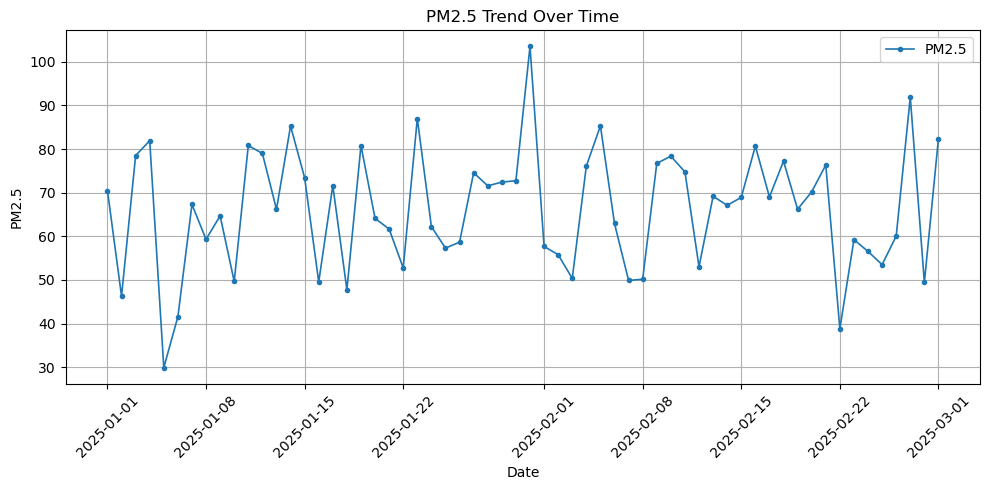

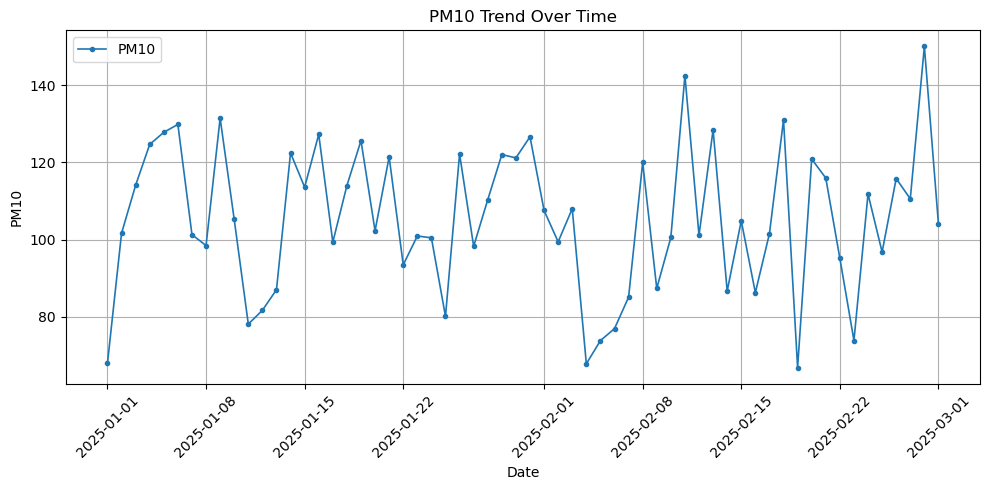

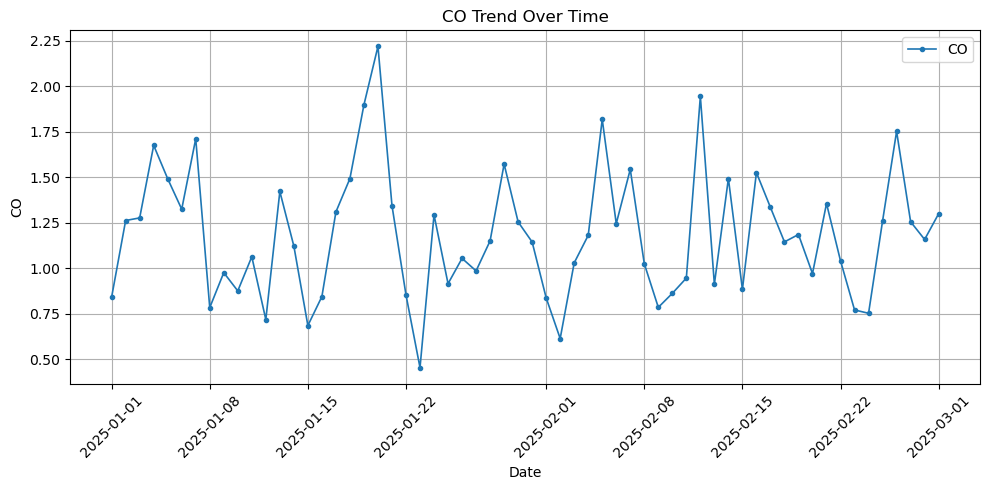

In [6]:
if date_col and pollutant_cols:
    plot_df = df.dropna(subset=[date_col]).sort_values(date_col)
    for col in pollutant_cols:
        if pd.api.types.is_numeric_dtype(plot_df[col]):
            plt.figure()
            plt.plot(plot_df[date_col], plot_df[col], marker=".", linewidth=1.2, label=col)
            plt.title(f"{col} Trend Over Time")
            plt.xlabel("Date")
            plt.ylabel(col)
            plt.legend()
            plt.xticks(rotation=45)
            plt.tight_layout()
            plt.show()
else:
    print("Pollutant trend plots skipped because required variables were not identified.")

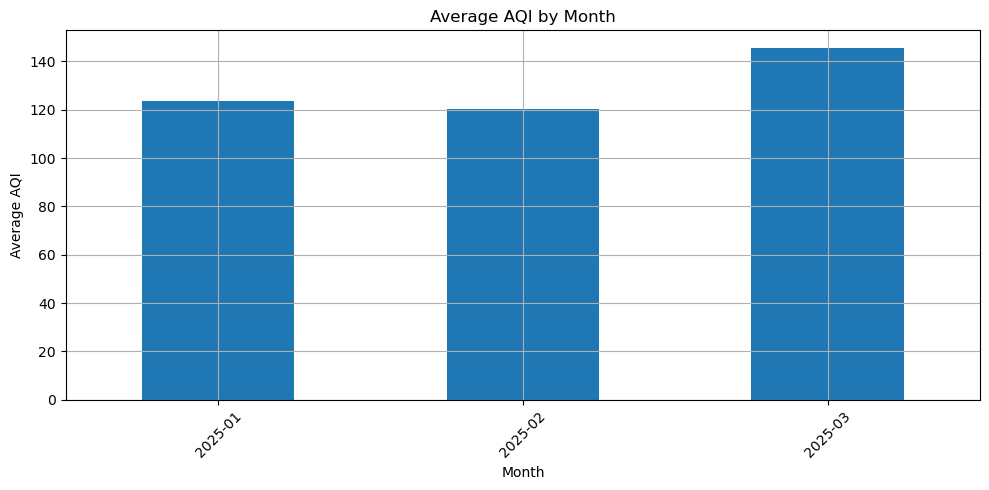

In [7]:
if date_col and aqi_col:
    plot_df = df.dropna(subset=[date_col, aqi_col]).sort_values(date_col).copy()
    plot_df["Period"] = plot_df[date_col].dt.to_period("M").astype(str)
    period_aqi = plot_df.groupby("Period")[aqi_col].mean()
    plt.figure()
    period_aqi.plot(kind="bar")
    plt.title("Average AQI by Month")
    plt.xlabel("Month")
    plt.ylabel("Average AQI")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("Time-period AQI comparison skipped.")

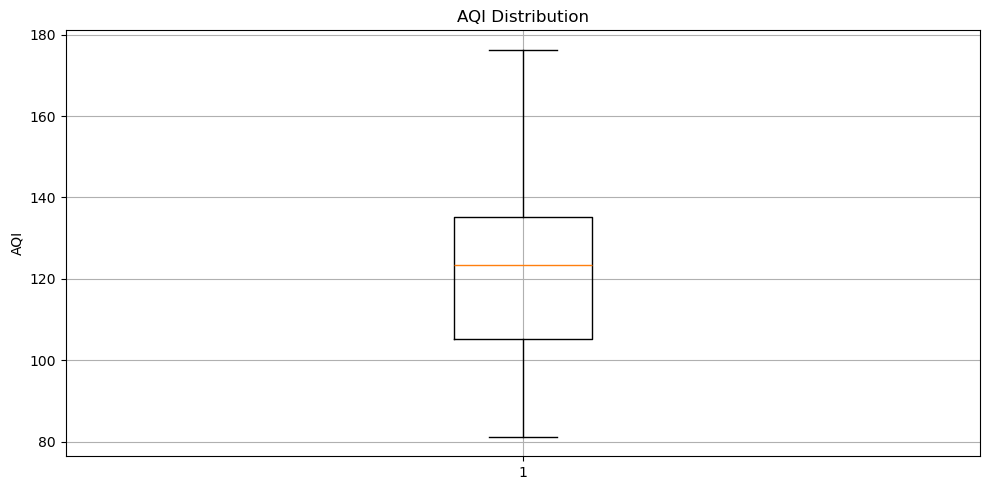

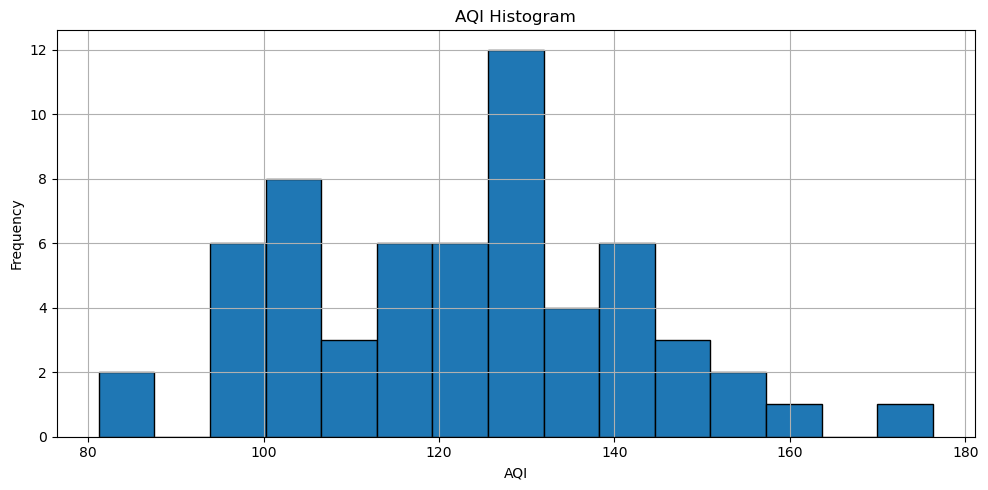

In [8]:
if aqi_col:
    plt.figure()
    plt.boxplot(df[aqi_col].dropna(), vert=True)
    plt.title("AQI Distribution")
    plt.ylabel("AQI")
    plt.tight_layout()
    plt.show()

    plt.figure()
    plt.hist(df[aqi_col].dropna(), bins=15, edgecolor="black")
    plt.title("AQI Histogram")
    plt.xlabel("AQI")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()
else:
    print("AQI distribution plots skipped.")

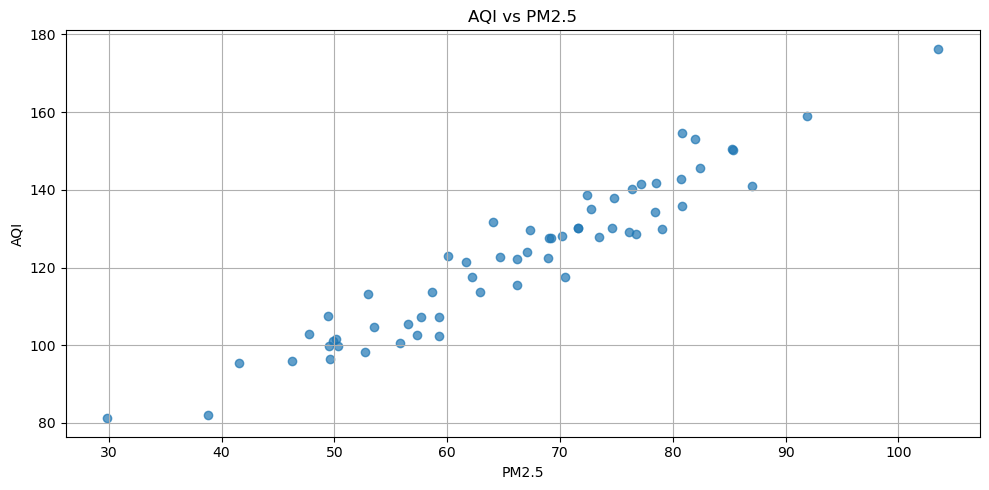

Correlation between AQI and PM2.5: 0.958


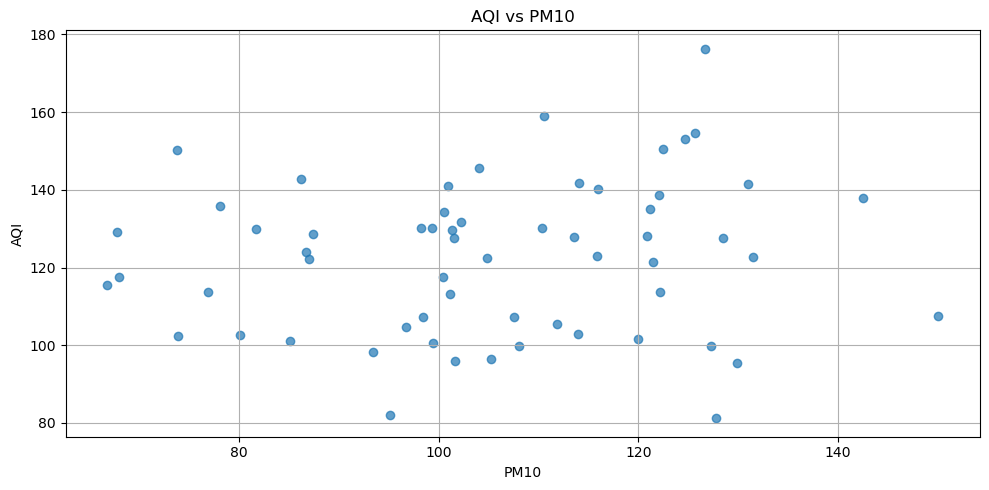

Correlation between AQI and PM10: 0.117


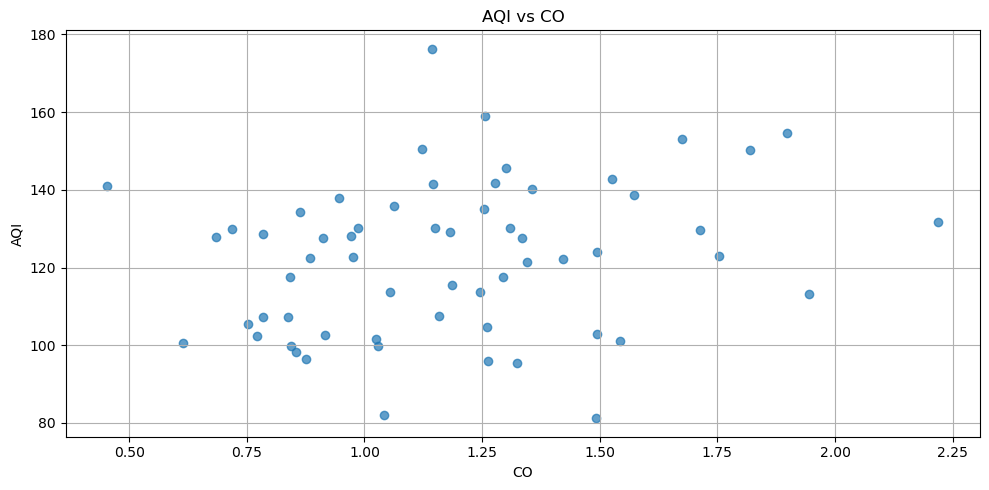

Correlation between AQI and CO: 0.235


In [9]:
if aqi_col:
    for col in pollutant_cols:
        if pd.api.types.is_numeric_dtype(df[col]):
            temp = df[[aqi_col, col]].dropna()
            plt.figure()
            plt.scatter(temp[col], temp[aqi_col], alpha=0.7)
            plt.title(f"AQI vs {col}")
            plt.xlabel(col)
            plt.ylabel("AQI")
            plt.tight_layout()
            plt.show()

            if len(temp) > 1:
                print(f"Correlation between AQI and {col}: {temp[aqi_col].corr(temp[col]):.3f}")
else:
    print("Scatter plots skipped.")